# Chapitre 8 - Cours 4 : pauses de processus, majorité, baux et jetons de clôture

Un nœud qui détient un **bail** (un verrou à durée limitée) peut s'endormir au pire moment
et se réveiller sans savoir qu'il a dormi, alors que les autres l'ont déclaré mort et
ont donné son bail à un autre. Ce notebook montre pourquoi cela arrive, pourquoi un nœud
ne peut pas se fier à son propre jugement, et comment le **jeton de clôture** empêche un
tel « zombie » de corrompre les données. Il couvre la section *Process Pauses* (*Response time guarantees*,
*Limiting the impact of garbage collection*) et le début de *Knowledge, Truth, and Lies* :
*The Truth Is Defined by the Majority* (*The leader and the lock*, *Fencing tokens*).

**Plan.**

1. Le bail et la boucle naïve : un processus peut s'arrêter n'importe où.
2. Garanties de temps de réponse et ramasse-miettes.
3. La majorité fait loi.
4. Verrous et baux distribués : la corruption par un zombie.
5. Les jetons de clôture.

In [1]:
import os
import signal
import subprocess
import sys
import textwrap
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import distsys as ds
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.requirements import plain_log_axis
from ddia.sim import Network
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

## 1. Le bail et la boucle naïve (section *Process Pauses*)

Dans une base où chaque partition a un leader unique, seul le leader
accepte les écritures. Comment un nœud sait-il qu'il est **encore** leader, que les
autres ne l'ont pas déclaré mort ? Une solution est le **bail** (lease) : un verrou
assorti d'une durée, accordé par les autres nœuds ou par un service de verrous. Tant que
le bail court, le nœud se sait leader ; il doit le **renouveler** avant expiration, et
s'il tombe, il cesse de le renouveler et un autre prend la relève. La boucle de
traitement ressemble à ceci (transcription en Python de l'exemple du livre) :

```python
while True:
    requete = attendre_requete()
    # garder au moins 10 secondes de marge sur le bail
    if bail.expiration - time.time() < 10:
        bail = bail.renouveler()
    if bail.est_valide():
        traiter(requete)          # <- et si le processus s'arrête juste avant ?
```

Deux défauts :

1. l'expiration a été fixée par **une autre machine** (son heure + 30 s) et on la compare
   à l'horloge **locale** : si les horloges divergent de quelques secondes, le code fait
   n'importe quoi (cours 3) ;
2. même avec une horloge monotone locale, le code suppose que **presque rien** ne se passe
   entre la vérification et le traitement. Si le fil d'exécution s'arrête 15 secondes
   juste après `est_valide()`, le bail a expiré quand la requête est traitée, un autre
   nœud est peut-être déjà leader, et rien ne prévient le fil qu'il a dormi.

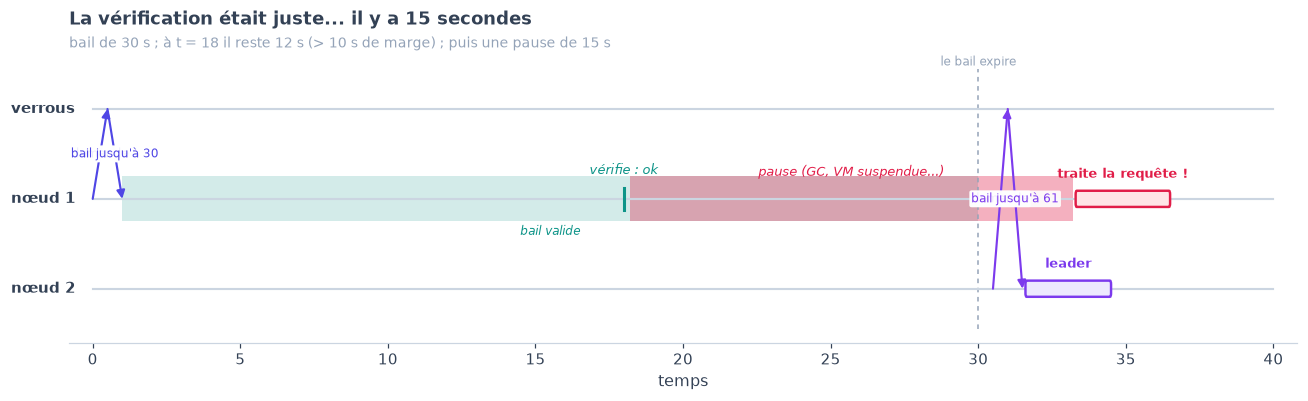

In [2]:
st = SpaceTime(["verrous", "nœud 1", "nœud 2"], t_max=40, width=12,
               title="La vérification était juste... il y a 15 secondes",
               subtitle="bail de 30 s ; à t = 18 il reste 12 s (> 10 s de marge) ; puis une pause de 15 s")
st.msg("nœud 1", 0.0, "verrous", 0.5, "demande", color=INDIGO)
st.msg("verrous", 0.5, "nœud 1", 1.0, "bail jusqu'à 30", color=INDIGO)
st.span("nœud 1", 1.0, 30.0, "bail valide", color=TEAL, alpha=0.18)
st.event("nœud 1", 18.0, "", kind="tick", color=TEAL)
st.note(18.0, "nœud 1", "vérifie : ok", dy=0.32, color=TEAL)
st.span("nœud 1", 18.2, 33.2, "", color=ROSE, alpha=0.35)
st.note(25.7, "nœud 1", "pause (GC, VM suspendue...)", dy=0.3, color=ROSE)
st.vline(30.0, "le bail expire")
st.msg("nœud 2", 30.5, "verrous", 31.0, "demande", color=VIOLET)
st.msg("verrous", 31.0, "nœud 2", 31.5, "bail jusqu'à 61", color=VIOLET)
st.op("nœud 2", 31.6, 34.5, "leader", color=VIOLET)
st.op("nœud 1", 33.3, 36.5, "traite la requête !", color=ROSE)
st.show()

**Est-il réaliste qu'un fil s'arrête aussi longtemps ?** Oui, pour bien des raisons :

| cause | durée typique |
|---|---|
| contention sur un verrou ou une file partagés | ms à s |
| ramasse-miettes « stop-the-world » (JVM...) | ms ; jadis jusqu'à plusieurs minutes |
| suspension puis reprise d'une machine virtuelle, migration à chaud | s à minutes |
| portable dont on ferme le couvercle, téléphone en veille | minutes à heures |
| commutation de contexte, temps volé par l'hyperviseur (steal time) sous forte charge | ms à s |
| E/S disque synchrones (y compris un chargement de classe paresseux, un disque réseau) | ms à s |
| défaut de page, échange avec le disque (swap), voire écroulement (thrashing) | ms à minutes |
| signal `SIGSTOP` (Ctrl-Z), envoyé exprès ou par erreur | illimitée |

Le dernier cas se reproduit facilement. Lançons un petit processus qui, toutes les 10
ms, note l'heure de son horloge monotone ; pendant qu'il tourne, on lui envoie `SIGSTOP`,
puis `SIGCONT` une seconde plus tard.

In [3]:
code = textwrap.dedent("""
    import time, sys
    t0 = last = time.monotonic(); trous = []
    while time.monotonic() - t0 < 2.0:
        time.sleep(0.01)
        now = time.monotonic()
        if now - last > 0.05:
            trous.append((round(last - t0, 3), round(now - last, 3)))
        last = now
    print(trous)
""")
p = subprocess.Popen([sys.executable, "-c", code], stdout=subprocess.PIPE, text=True)
time.sleep(0.4)
os.kill(p.pid, signal.SIGSTOP)
time.sleep(1.0)
os.kill(p.pid, signal.SIGCONT)
out, _ = p.communicate(timeout=10)
trous = eval(out)
print("trous observés par le processus (début, durée en s) :", trous)

trous observés par le processus (début, durée en s) : [(0.382, 1.006)]


Le processus n'a rien vu sur le moment : il a simplement constaté, **après coup** et
seulement parce qu'il relisait son horloge, qu'une de ses itérations de 10 ms avait duré
une seconde. Un nœud d'un système distribué doit supposer que son exécution peut être
suspendue longtemps **à n'importe quel point**, même au milieu d'une fonction ; pendant
ce temps, le reste du monde avance et peut le déclarer mort.

Sur une seule machine, on a des outils pour le code concurrent (mutex, sémaphores,
compteurs atomiques, files bloquantes). Ils ne se transposent pas au distribué : il n'y
a **pas de mémoire partagée**, seulement des messages sur un réseau non fiable.

**Combien de temps peut durer une pause ?** Le module fournit un générateur de pauses
synthétiques (`ds.gc_pause_samples`) : surtout des petites collectes de quelques
millisecondes, et, deux fois sur mille, une longue pause à queue lourde (collecte
complète, échange de pages, suspension de VM).

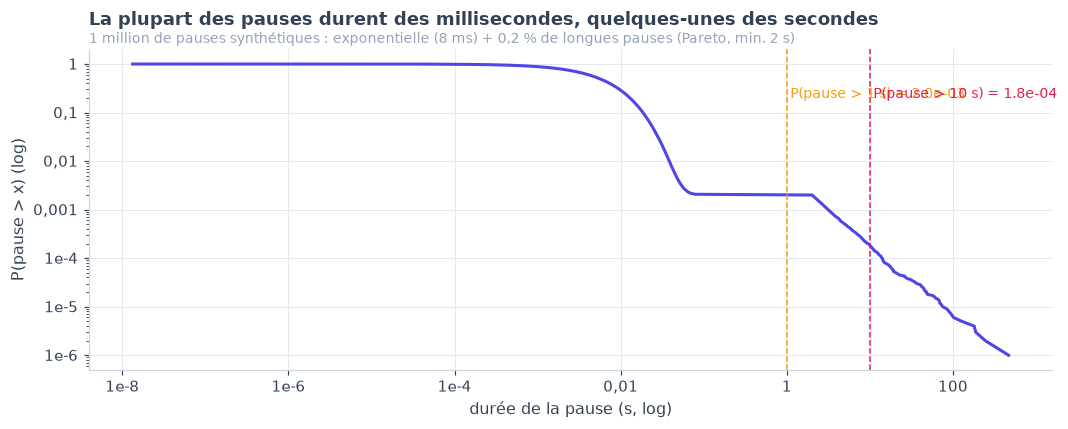

avec 10 pauses par seconde, pauses de plus de 10 s attendues par jour : 159


In [4]:
pauses = ds.gc_pause_samples(1_000_000, seed=1)
xs = np.sort(pauses)
idx = np.unique(np.r_[np.arange(0, xs.size, 400), xs.size - np.geomspace(1, xs.size // 2, 300).astype(int)])
fig, ax = plt.subplots(figsize=(10, 4))
ax.loglog(xs[idx], 1 - idx / xs.size, color=INDIGO)
for m, c in [(1, AMBER), (10, ROSE)]:
    pm = (pauses > m).mean()
    ax.axvline(m, color=c, ls="--", lw=1)
    ax.text(m * 1.1, 0.2, f"P(pause > {m} s) = {pm:.1e}", color=c, fontsize=9)
plain_log_axis(ax)
ax.set_xlabel("durée de la pause (s, log)"); ax.set_ylabel("P(pause > x) (log)")
ax.set_title("La plupart des pauses durent des millisecondes, quelques-unes des secondes")
subtitle(ax, "1 million de pauses synthétiques : exponentielle (8 ms) + 0,2 % de longues pauses (Pareto, min. 2 s)")
plt.tight_layout(); plt.show()
p10 = (pauses > 10).mean()
print(f"avec 10 pauses par seconde, pauses de plus de 10 s attendues par jour : {p10 * 10 * 86400:.0f}")

Une pause sur cinq mille environ dépasse 10 secondes, la marge de la boucle naïve. Avec
une dizaine de pauses par seconde, cela fait plus d'une centaine par jour : la marge ne
protège de rien, elle rend seulement le problème plus rare.

> **À retenir.** Un processus peut être suspendu à n'importe quel endroit de son code,
> pendant une durée non bornée, sans le savoir. Vérifier un bail puis agir n'est donc
> pas sûr, quelle que soit la marge.